Start by importing packages and fire dataset, then subset to 2025. 

In [1]:
# import packages
import platform
from pathlib import Path
import pandas as pd
import geopandas as gpd
import seaborn as sns
import calendar
import matplotlib.pyplot as plt
import pygris

In [15]:
# import dataset
# parents.[1] suggested by copilot ai 
# to direct project folder to top of directory
project_fldr = Path.cwd().parents[1]

raw_fldr = project_fldr / 'data' / 'raw'
processed_fldr = project_fldr / 'data' / 'processed'

# read in CSV
fire_perims = pd.read_csv(raw_fldr / 'California_Historic_Fire_Perimeters_4486510518992991706.csv')

# convert alarm date, containment date to datetime objects
# want year to not include a day/month so will convert to string for now
fire_perims["Year"] = fire_perims["Year"].astype("Int64")

# alarm date and containment date have date/time included
fire_perims["Alarm Date"] = pd.to_datetime(fire_perims["Alarm Date"], format="%m/%d/%Y %I:%M:%S %p")
fire_perims["Containment Date"] = pd.to_datetime(fire_perims["Containment Date"], format="%m/%d/%Y %I:%M:%S %p")
fire_perims.info()

# report number of rows and columns 
fire_perims.shape


<class 'pandas.DataFrame'>
RangeIndex: 11139 entries, 0 to 11138
Data columns (total 22 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   OBJECTID                      11139 non-null  int64         
 1   Year                          11068 non-null  Int64         
 2   State                         11139 non-null  str           
 3   Agency                        11091 non-null  str           
 4   Unit ID                       11086 non-null  str           
 5   Fire Name                     8363 non-null   str           
 6   Local Incident Number         10366 non-null  str           
 7   IRWIN ID                      1882 non-null   str           
 8   Alarm Date                    8566 non-null   datetime64[us]
 9   Containment Date              5543 non-null   datetime64[us]
 10  Cause                         11139 non-null  str           
 11  Collection Method             11139 non

(11139, 22)

In [3]:
fire_perims.head()


,OBJECTID,Year,State,Agency,Unit ID,Fire Name,Local Incident Number,IRWIN ID,Alarm Date,Containment Date,...,Management Objective,GIS Calculated Acres,Comments,Complex Name,Complex ID,Fire Number (historical use),GlobalID,Decade,Shape__Area,Shape__Length
0,2917,2018,California,California Department of Forestry and Fire Pro...,Madera - Mariposa CAL FIRE,NEES,00008764,{2BF1495F-153B-4EAB-99B2-1BF95ACE603D},2018-05-02,2018-05-02,...,Suppression (Wildfire),1739.06900,NaN,NaN,NaN,NaN,e629405b-4ee6-40fa-8089-7f73dec5ae3a,2010-2019,1.101012e+07,21616.185914
1,3581,2017,California,USDA Forest Service,Sequoia National Forest,TRAIL,00002157,{7E50CF54-EB87-4D2D-B3A0-6E45E0366310},2017-08-12,2018-01-15,...,Suppression (Wildfire),31.87081,CONT_DATE based on FIRESTAT Fire Out Date/Time,NaN,NaN,NaN,168ff39b-2799-4ecf-a65a-9f1a77f1156d,2010-2019,2.009375e+05,3274.045296
2,261,2025,California,California Department of Forestry and Fire Pro...,Tuolumne - Calaveras CAL FIRE,GRANGE,00006367,{D405E0AF-DF6F-4FCA-9E8F-DB2D090E46CC},2025-05-18,2025-05-18,...,Suppression (Wildfire),19.91957,NaN,NaN,NaN,NaN,830225d4-d69c-41fe-9665-069134892a49,2020-2025,1.288790e+05,1586.431281
3,7826,2004,California,California Department of Forestry and Fire Pro...,Madera - Mariposa CAL FIRE,DAMET,00007425,NaN,2004-04-30,2004-04-30,...,Suppression (Wildfire),33.48191,NaN,NaN,NaN,00000106,5cc43fac-d0e6-4cd6-a47b-557836eccbd3,2000-2009,2.134281e+05,1844.766476
4,21486,1922,California,USDA Forest Service,Sierra National Forest,NaN,00000000,NaN,NaT,NaT,...,Suppression (Wildfire),797.90860,NaN,NaN,NaN,00000001,0af2ae75-ac8d-4588-8772-8b616c4ea611,NaN,5.131397e+06,9008.227814


In [4]:
# subset to 2025
fire_perims_25 = fire_perims[fire_perims['Year'] == 2025]
fire_perims_25.head()

# see if there are na values
print(fire_perims_25.isna().sum())

print(fire_perims_25.isna().mean().sort_values(ascending=False) * 100)

# note there is one fire without a containment date, but we will still keep it in the dataset
# drop some columns that are not needed for analysis and have missing data
# fire_perims_25 = fire_perims_25.drop(columns=['OBJECTID', 'Unit ID', 'Local Incident Number', 'IRWIN ID', 'Comments', 'GlobalID',
#'Fire Number (historical use)','Complex ID', 'Complex Name'])

OBJECTID                          0
Year                              0
State                             0
Agency                            0
Unit ID                           0
Fire Name                         0
Local Incident Number             0
IRWIN ID                          0
Alarm Date                        0
Containment Date                  1
Cause                             0
Collection Method                 0
Management Objective              0
GIS Calculated Acres              0
Comments                        197
Complex Name                    231
Complex ID                      231
Fire Number (historical use)    243
GlobalID                          0
Decade                            0
Shape__Area                       0
Shape__Length                     0
dtype: int64
Fire Number (historical use)    100.000000
Complex ID                       95.061728
Complex Name                     95.061728
Comments                         81.069959
Containment Date       

Learn about the dataset
- Rows/columns
- Column titles
- NA data
- Column statistics

In [5]:
# percent of missing data for each column after removing columns
misper = fire_perims_25.isna().mean().sort_values(ascending=False) * 100
print('The percent of missing data for each column is:', misper)

# add a column for month of alarm date
fire_perims_25['Alarm Month'] = fire_perims_25['Alarm Date'].dt.month

fire_perims_25['Alarm Month Abb'] = pd.Categorical(
    values = fire_perims_25['Alarm Date'].dt.month_name().str[:3],
    categories=calendar.month_abbr[1:]
)


The percent of missing data for each column is: Fire Number (historical use)    100.000000
Complex ID                       95.061728
Complex Name                     95.061728
Comments                         81.069959
Containment Date                  0.411523
OBJECTID                          0.000000
Management Objective              0.000000
Shape__Area                       0.000000
Decade                            0.000000
GlobalID                          0.000000
GIS Calculated Acres              0.000000
Collection Method                 0.000000
Year                              0.000000
Cause                             0.000000
Alarm Date                        0.000000
IRWIN ID                          0.000000
Local Incident Number             0.000000
Fire Name                         0.000000
Unit ID                           0.000000
Agency                            0.000000
State                             0.000000
Shape__Length                     0.000000
dtype:

Answer some basic questions about the fire dataset: 
- How are the 2025 fires distributed temporally? 
    - A majority of the 2025 fires occur during summer months, from May to September
- What are the sizes of the 2025 fires? 
    - The sizes of the fires range from a fraction of an acre to very large, almost 100000 acres. However, a majority of the recorded fires were between 10 and 100 acres, relatively small. 
- How are the fires distributed spatially?


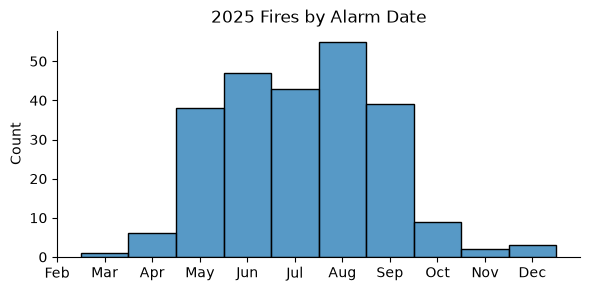

In [12]:
# Plot number of fires by month

g = sns.displot(
    data = fire_perims_25,
    x = 'Alarm Month Abb',
    height=3,
    aspect=2
)

g.set(
    title = "2025 Fires by Alarm Date",
    xlabel="",
    ylabel="Count"
);



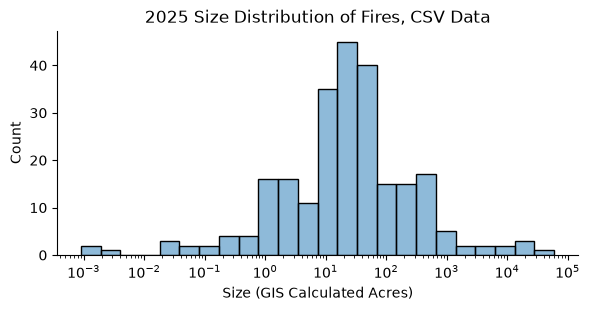

In [13]:
# Size distribution figure
g = sns.displot(
    data = fire_perims_25,
    x = 'GIS Calculated Acres',
    kind='hist',
    height=3,
    aspect=2,
    alpha=0.5,
    log_scale=True # choose to use log scale to display data that is heavily skewed
)

g.set(
    title = "2025 Size Distribution of Fires, CSV Data",
    xlabel="Size (GIS Calculated Acres)",
    ylabel="Count"
);



In [6]:
# Now we need to look at the fire perimeter shapefile 
# Also needs to be accessed through Box, and shapefile is inside .gdb
# fire perimeter layer name firep25_1

# set a path to the main box folder based on machine's os
# if windows: 
if platform.system() == 'Windows':
    box_path = Path.home() / 'Box'
# if mac:
else:
    box_path = Path.home() / "Library" / "CloudStorage" / "Box-Box"

#Confirm that the box path is valid
if box_path.exists():
    print(f'Box folder found at {box_path}')
else:
    print(f'Failed to locate the Box folder.\nIs the BoxDrive app running?\nAre you logged in?')

# create path object that goes to the specific folder on Box drive
# uploading wetlands that are bigger than a hectare
fire_path = box_path / 'ENVIRON 712L-Students' / 'Data' / 'BunkerAndersonTseng' / 'fire25_1.gdb'
print(fire_path.exists())

fire_shp = gpd.read_file(fire_path, layer='firep25_1')



Box folder found at /Users/katanderson/Library/CloudStorage/Box-Box
True


/Users/katanderson/miniforge3/envs/env700/lib/python3.13/site-packages/pyogrio/raw.py:200: RuntimeWarning: organizePolygons() received a polygon with more than 100 parts. The processing may be really slow.  You can skip the processing by setting METHOD=SKIP, or only make it analyze counter-clock wise parts by setting METHOD=ONLY_CCW if you can assume that the outline of holes is counter-clock wise defined. Further messages of this type will be suppressed.
  return ogr_read(
/Users/katanderson/miniforge3/envs/env700/lib/python3.13/site-packages/pyogrio/raw.py:200: RuntimeWarning: organizePolygons() received a polygon with more than 100 parts.  The processing may be really slow.  You can skip the processing by setting METHOD=SKIP. Further messages of this type will be suppressed.
  return ogr_read(


In [10]:
# inspect shapefile data - similar columns but less information than the CSV file
# But we can join them



# add a column for month of alarm date
fire_shp['Alarm Month'] = fire_shp['ALARM_DATE'].dt.month

fire_shp['Alarm Month Abb'] = pd.Categorical(
    values = fire_shp['ALARM_DATE'].dt.month_name().str[:3],
    categories=calendar.month_abbr[1:]
)

# look at columns, data types, counts
fire_shp.info()
fire_shp.head()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 23334 entries, 0 to 23333
Data columns (total 23 columns):
 #   Column           Non-Null Count  Dtype              
---  ------           --------------  -----              
 0   YEAR_            23257 non-null  float64            
 1   STATE            23334 non-null  str                
 2   AGENCY           23286 non-null  str                
 3   UNIT_ID          23274 non-null  str                
 4   FIRE_NAME        16751 non-null  str                
 5   INC_NUM          22379 non-null  str                
 6   IRWINID          3634 non-null   str                
 7   ALARM_DATE       17950 non-null  datetime64[ms, UTC]
 8   CONT_DATE        10716 non-null  datetime64[ms, UTC]
 9   C_METHOD         23334 non-null  int16              
 10  CAUSE            23334 non-null  int16              
 11  OBJECTIVE        23063 non-null  float64            
 12  GIS_ACRES        23334 non-null  float32            
 13  COMPLEX_

,YEAR_,STATE,AGENCY,UNIT_ID,FIRE_NAME,INC_NUM,IRWINID,ALARM_DATE,CONT_DATE,C_METHOD,...,COMPLEX_ID,COMPLEX_NAME,COMMENTS,FIRE_NUM,Shape_Length,Shape_Area,GlobalID,geometry,Alarm Month,Alarm Month Abb
0,2025.0,CA,USF,LPF,GIFFORD,00002181,{08A6358F-8301-4093-9988-E265C8F6F0A9},2025-08-01 00:00:00+00:00,2025-10-14 00:00:00+00:00,3,...,NaN,NaN,NaN,NaN,257388.320379,5.326211e+08,{E87207FF-BD3D-4836-8A89-AD218A20B17E},"MULTIPOLYGON (((-35131.146 -302750.005, -35107...",8.0,Aug
1,2025.0,CA,USF,LPF,MADRE,00001817,{1AB682F7-CC0F-4DCE-87A4-FA4A9B67AB05},2025-07-02 00:00:00+00:00,2025-07-26 00:00:00+00:00,7,...,NaN,NaN,NaN,NaN,191846.167384,3.269014e+08,{C59C71E2-F79F-440B-8C84-48058988F3CF},"MULTIPOLYGON (((-4405.284 -313794.721, -4405.4...",7.0,Jul
2,2025.0,CA,USF,SNF,GARNET,00001684,{68B988A1-C190-4F0C-9BEA-A658D389D167},2025-08-24 00:00:00+00:00,2025-10-23 00:00:00+00:00,3,...,NaN,NaN,NaN,NaN,234717.355087,2.428892e+08,{DDD0B278-7655-4F20-829D-FEEEF1DC935F},"MULTIPOLYGON (((89617.826 -122364.58, 89614.97...",8.0,Aug
3,2025.0,CA,CDF,FKU,SALT,00018739,{7F4A1474-6439-44F3-8F0D-083DCFD33639},2025-09-02 00:00:00+00:00,2025-09-17 00:00:00+00:00,7,...,NaN,NaN,Park incident clipped out per BEU,NaN,90080.360959,1.034115e+08,{6817A72C-90CF-4CD4-8F26-2B9622F1F140},"MULTIPOLYGON (((-31970.799 -229822.278, -31947...",9.0,Sep
4,2025.0,CA,CDF,LDF,PALISADES,00000738,{A7EA5D21-F882-44B8-BF64-44AB11059DC1},2025-01-07 00:00:00+00:00,2025-01-31 00:00:00+00:00,7,...,NaN,NaN,NaN,NaN,116028.197349,9.489426e+07,{73730F90-5D60-4850-98C2-2431C4284CD7},"MULTIPOLYGON (((136696.228 -441776.379, 136683...",1.0,Jan


In [12]:
# look at na values
misper = (fire_shp.isna().mean().sort_values(ascending=False) * 100)
print('The percent of missing data for each column is:', misper)

# subset to 2025
fire_shp_25 = fire_shp[fire_shp['YEAR_'] == 2025]
fire_shp_25.head()

# look at na values
misper = (fire_shp_25.isna().mean().sort_values(ascending=False) * 100)
print('The percent of missing data for each column is:', misper)


The percent of missing data for each column is: COMPLEX_ID         97.492929
COMPLEX_NAME       97.351504
COMMENTS           87.306077
IRWINID            84.426159
CONT_DATE          54.075598
FIRE_NAME          28.212051
FIRE_NUM           24.402160
Alarm Month Abb    23.073626
Alarm Month        23.073626
ALARM_DATE         23.073626
INC_NUM             4.092740
OBJECTIVE           1.161395
YEAR_               0.329991
UNIT_ID             0.257136
AGENCY              0.205708
GIS_ACRES           0.000000
STATE               0.000000
CAUSE               0.000000
C_METHOD            0.000000
Shape_Length        0.000000
Shape_Area          0.000000
GlobalID            0.000000
geometry            0.000000
dtype: float64
The percent of missing data for each column is: FIRE_NUM           100.000000
COMPLEX_ID          96.737044
COMPLEX_NAME        96.737044
COMMENTS            76.967370
IRWINID              9.980806
CONT_DATE            1.343570
YEAR_                0.000000
Alarm Month 

Next, I want to visualize the fire perimeter shapefile. I also want to include CA state boundaries, so I am using the pygris package to access US Census Bureau tiger/line shapefiles without downloading them. 
- to install pygris in environment, run %pip install pygris in a cell
- https://github.com/walkerke/pygris

Then I am using matplot and geopandas to make the map!

Using the default year of 2024


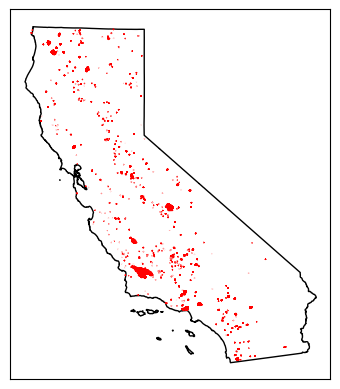

In [17]:
# make a plot of 2025 fire perimeter shapefile
state_outlines = pygris.states()
state_outlines.head()
ca_outline = state_outlines[state_outlines['NAME'] == 'California']

# make sure CA and fire shapefile are in same CRS
ca_outline_proj= ca_outline.to_crs(fire_shp_25.crs)


# create the empty plot

fig, ax = plt.subplots()
# add the CA outline
ca_outline_proj.plot(ax=ax,color='white',edgecolor='black')
# add the fire perimeters
fire_shp_25.plot(ax=ax,figsize=(10,10), color='red', edgecolor='red')

# consult google gemini to learn how to turn axes off
ax.axis=('off')
ax.get_xaxis().set_visible(False) # Explicitly hide X elements
ax.get_yaxis().set_visible(False)

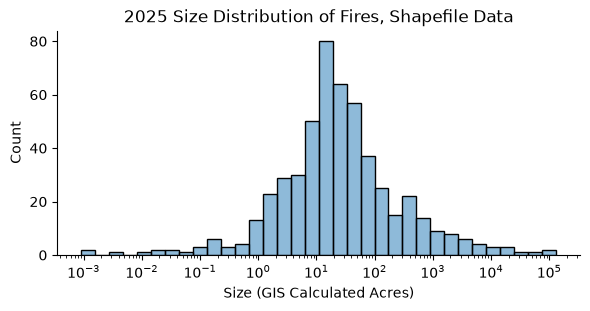

In [18]:
# look also at size distribution of the fires recorded in the shapefile

g = sns.displot(
    data = fire_shp_25,
    x = 'GIS_ACRES',
    kind='hist',
    height=3,
    aspect=2,
    alpha=0.5,
    log_scale=True # choose to use log scale to display data that is heavily skewed
)

g.set(
    title = "2025 Size Distribution of Fires, Shapefile Data",
    xlabel="Size (GIS Calculated Acres)",
    ylabel="Count"
);

- Finally, I want to merge my shapefile data with CSV data, but the IRWINID key is missing a lot of data, making it hard to match the datasets together.
- We are also facing another big data limitation - we have many fire records that don't have shapefiles associated. 


In [19]:
# look at column headers
print(fire_shp_25.columns)
print(fire_perims.columns)

# look at rows/columns again
print('fire shapefile records:', fire_shp_25.shape)
print('fire perimeter records:', fire_perims.shape) 


Index(['YEAR_', 'STATE', 'AGENCY', 'UNIT_ID', 'FIRE_NAME', 'INC_NUM',
       'IRWINID', 'ALARM_DATE', 'CONT_DATE', 'C_METHOD', 'CAUSE', 'OBJECTIVE',
       'GIS_ACRES', 'COMPLEX_ID', 'COMPLEX_NAME', 'COMMENTS', 'FIRE_NUM',
       'Shape_Length', 'Shape_Area', 'GlobalID', 'geometry'],
      dtype='str')
Index(['OBJECTID', 'Year', 'State', 'Agency', 'Unit ID', 'Fire Name',
       'Local Incident Number', 'IRWIN ID', 'Alarm Date', 'Containment Date',
       'Cause', 'Collection Method', 'Management Objective',
       'GIS Calculated Acres', 'Comments', 'Complex Name', 'Complex ID',
       'Fire Number (historical use)', 'GlobalID', 'Decade', 'Shape__Area',
       'Shape__Length'],
      dtype='str')
fire shapefile records: (521, 21)
fire perimeter records: (11139, 22)


In [23]:
#see if we can match by Gis Acres, if there aren't duplicates
acres_shp = fire_shp_25['GIS_ACRES'].duplicated().sum()
acres_csv = fire_perims_25['GIS Calculated Acres'].duplicated().sum()
print(acres_shp, acres_csv) # there are no duplicates!!

# use gis acres as key for join
all_fire_25 = pd.merge(
    fire_shp_25,
    fire_perims_25,
    left_on="GIS_ACRES",
    right_on="GIS Calculated Acres",
    how="left",
)

#drop some columns that are not needed for analysis and have missing data
all_fire_25 = fire_perims_25.drop(columns=['GIS Calculated Acres','OBJECTID', 'Unit ID', 'Local Incident Number', 'IRWIN ID', 'Comments', 'GlobalID',
'Fire Number (historical use)','Complex ID', 'Complex Name'])
print(all_fire_25.shape)

misper = (fire_shp.isna().mean().sort_values(ascending=False) * 100)
print('The percent of missing data for each column is:', misper)



0 0
(243, 14)
The percent of missing data for each column is: COMPLEX_ID      97.492929
COMPLEX_NAME    97.351504
COMMENTS        87.306077
IRWINID         84.426159
CONT_DATE       54.075598
FIRE_NAME       28.212051
FIRE_NUM        24.402160
ALARM_DATE      23.073626
INC_NUM          4.092740
OBJECTIVE        1.161395
YEAR_            0.329991
UNIT_ID          0.257136
AGENCY           0.205708
GlobalID         0.000000
Shape_Area       0.000000
Shape_Length     0.000000
CAUSE            0.000000
GIS_ACRES        0.000000
STATE            0.000000
C_METHOD         0.000000
geometry         0.000000
dtype: float64


Data Quality Audit: 
Our biggest challenge with the fire dataset will be dealing with all of the missing values, most of which are associated with the shapefile. As time allows, the CalFire website will be revisited to see if a more complete dataset exists, because the CSV contains more fires, but without the available footprints needed to compare to spatial distribution of wetlands. If a shapefile without missing IRWINID exists, that would be extremely helpful for the join because all fires are given a unique IRWINID. 

We began with (rows,columns): (521, 21) and fire perimeter records: (11139, 22), but after joining we are left with (243, 14). Some columns with information deemed unimportant that also contained missing values or were duplicates were dropped: 'GIS Calculated Acres','OBJECTID', 'Unit ID', 'Local Incident Number', 'IRWIN ID', 'Comments', 'GlobalID', 'Fire Number (historical use)','Complex ID', 'Complex Name'. 

For the next part of our project, we have decided to continue using the CalFire Fire Perimeters Shapefile data, because although it does not include as many attributes as the CSV, it has the necessary spatial components needed for comparison with the wetlands file, and a join between the two severely reduced the amount of data available to us.



In [ ]:
# save cleaned shapefile in processed folder
project_fldr = Path.cwd().parents[1]

raw_fldr = project_fldr / 'data' / 'raw'
processed_fldr = project_fldr / 'data' / 'processed'

fire_shp_25.to_file(processed_fldr / "fire_shp_25", driver="ESRI Shapefile")


/var/folders/p2/ldqdqlt90kdc24djt1y1h1g40000gn/T/ipykernel_73285/2020198845.py:7: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  fire_shp_25.to_file(processed_fldr / "fire_shp_25", driver="ESRI Shapefile")
/Users/katanderson/miniforge3/envs/env700/lib/python3.13/site-packages/pyogrio/raw.py:733: RuntimeWarning: Field ALARM_DATE created as String field, though DateTime requested.
  ogr_write(
/Users/katanderson/miniforge3/envs/env700/lib/python3.13/site-packages/pyogrio/raw.py:733: RuntimeWarning: Field CONT_DATE created as String field, though DateTime requested.
  ogr_write(
/Users/katanderson/miniforge3/envs/env700/lib/python3.13/site-packages/pyogrio/raw.py:733: RuntimeWarning: Normalized/laundered field name: 'COMPLEX_NAME' to 'COMPLEX_NA'
  ogr_write(
/Users/katanderson/miniforge3/envs/env700/lib/python3.13/site-packages/pyogrio/raw.py:733: RuntimeWarning: Normalized/laundered field name: 'Shape_Length' to 'Shape_Leng'
  ogr_w